# Random and structured directions

In [222]:
import torch

from eszd import SSZD
from eszd.directions import SphericalDirections, HouseholderQRDirections, RandomCoords, DirectionMatrix
import matplotlib.pyplot as plt

from math import sqrt

In [223]:
def target(x, z = None):
    return x.square().mean(dim=1)

In [ ]:

d = 100
l = d//5
alpha = lambda t: l/d * 20.0# * 1/sqrt(t)
h = lambda t : 1e-9 / sqrt(t)
gaussian_P = SphericalDirections(d=d, l=l, dtype=torch.float64)
structured_P = HouseholderQRDirections(d=d, l=l, dtype=torch.float64)

In [ ]:
opt_st = SSZD(structured_P, alpha=alpha, h=h)
opt_gd = SSZD(gaussian_P, alpha=alpha, h=h)

In [ ]:
T = 500
x0 = torch.full((1, d), 1e4)

ris_st = opt_st.optimize(target, x0, T=T)
ris_gd = opt_gd.optimize(target, x0, T=T)


In [ ]:
trace_st = []
trace_gd = []

for i in range(len(ris_st[2])):
    for _ in range(l):
        trace_st.append(ris_st[2][i])
        trace_gd.append(ris_gd[2][i])


In [ ]:
fig, ax = plt.subplots()
ax.plot(range(len(trace_gd)), trace_gd,'-', lw=3, label="random directions")
ax.plot(range(len(trace_st)), trace_st,'-', lw=3, label="structured directions")
ax.set_yscale("log")
ax.set_xlabel("function evaluations", fontsize=20)
ax.set_ylabel("$f(x)$", fontsize=20)
ax.legend(fontsize=14)
plt.savefig("structured_vs_random.pdf", bbox_inches='tight')



# Coordinate vs QR

In [410]:

class LinearRegression:
    
    def __init__(self, d = 5, seed = 32, device='cpu', dtype=torch.float32) -> None:
        self.gen = torch.Generator(device=device)
        self.gen.manual_seed(seed)
        self.X = torch.rand(size=(100, d), dtype=dtype) * 3 + 2
        self.w = torch.rand(size=(1, d), dtype=dtype)
        self.y =  self.w @ self.X.T
        
    def get_L(self):
        return torch.linalg.eigvalsh(self.X.T @ self.X)
        
    def __call__(self, w, z = None):
        if z is not None:
            x, y = self.X[z, :].reshape(1, -1), self.y[z, :].reshape(1, -1)
            y_pred = w @ x.T
        #    print(x.shape, w.shape)
        #   print(y.shape, y_pred.shape)
            mse =  (y - y_pred).norm(dim=1).square()
         #   print("MSE: {}".format(mse))
            return mse
        y_pred = w @ self.X.T
        return (self.y - y_pred).norm(dim=1).square()#.mean()
        
        


In [412]:
lr = LinearRegression(d = 5, dtype=torch.float64)

w = torch.ones((1, 5), dtype=torch.float64)

print(lr(w,0))

print(lr.get_L())


tensor([4824.6995], dtype=torch.float64)
tensor([6121.1713+0.j,   58.5249+0.j,   68.5293+0.j,   97.5948+0.j,   91.1946+0.j],
       dtype=torch.complex128)


In [404]:
from torch_dct import dct

class DCTDirections(DirectionMatrix):
    def __init__(self, d: int, l: int, mul_seed=12, mul_device='cpu', seed: int | None = None, dtype=torch.float32, device: str = 'cpu'):
        super().__init__(d, l, seed, dtype, device)
        self.mgen = torch.Generator(device=mul_device)
        self.mgen.manual_seed(mul_seed)
        self.I = torch.eye(d, d, dtype=self.dtype, device=mul_device)
        self.inds = torch.ones(self.d, device=self.device)

    

    def __call__(self):
        inds = self.inds.multinomial(self.l, replacement=False, generator=self.mgen)
        #print(self.I[:, inds])
        P = dct(self.I[:, inds].T, norm='ortho')
        return self.nrm_const * P.T
        

In [405]:
d = 500
l = d//5
target = LinearRegression(d = d, dtype=torch.float64)
coord_P = RandomCoords(d = d, l=l, dtype=torch.float64)
qr_P = HouseholderQRDirections(d = d, l=l, dtype = torch.float64)
dct_P = DCTDirections(d= d, l = l, dtype=torch.float64)


In [406]:

alpha_co = lambda t: l/d  * 80.0
alpha_qr = lambda t: l/d  * 80.0
h = lambda t : 1e-10# / t #sqrt(t)

opt_co = SSZD(coord_P, alpha=alpha_co, h=h)
opt_qr = SSZD(qr_P, alpha=alpha_qr, h=h)
opt_dct = SSZD(dct_P, alpha=alpha_qr, h=h)


In [407]:
T = 1000
x0 = torch.full((1, d), 100., dtype=torch.float64)

ris_co = opt_co.optimize(target, x0, T=T)
ris_qr = opt_qr.optimize(target, x0, T=T)
ris_dct = opt_dct.optimize(target, x0, T=T)

In [408]:
trace_co = []
trace_qr = []
trace_dct = []

for i in range(len(ris_co[2])):
    for _ in range(l):
        trace_co.append(ris_co[2][i])
        trace_qr.append(ris_qr[2][i])
        trace_dct.append(ris_dct[2][i])


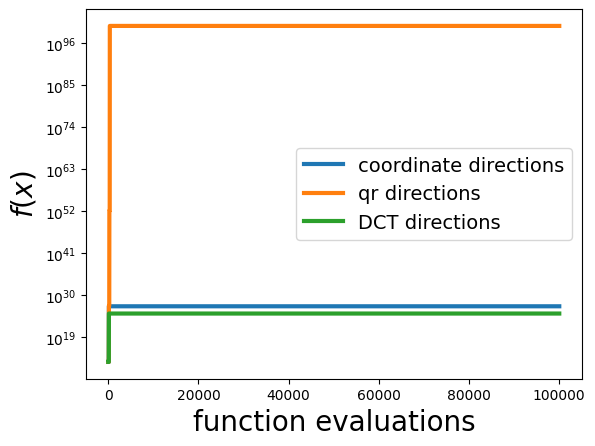

In [409]:
fig, ax = plt.subplots()
ax.plot(range(len(trace_co)), trace_co,'-', lw=3, label="coordinate directions")
ax.plot(range(len(trace_qr)), trace_qr,'-', lw=3, label="qr directions")
ax.plot(range(len(trace_dct)), trace_dct,'-', lw=3, label="DCT directions")
ax.set_yscale("log")
ax.set_xlabel("function evaluations", fontsize=20)
ax.set_ylabel("$f(x)$", fontsize=20)
ax.legend(fontsize=14)
#plt.savefig("structured_vs_random.pdf", bbox_inches='tight')